# Depth stability analysis

This notebook reads cached MD stability summaries. Run `depth_stability_analysis.py` first. Depth 0 is the white surface and depth 20 is the pial surface.

In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/depth_stability')
depth=pd.read_csv(ROOT/'depth_level_stability.csv')
region=pd.read_csv(ROOT/'region_level_stability.csv')
print(len(depth),'depth rows;',len(region),'region rows')

427077 depth rows; 20337 region rows


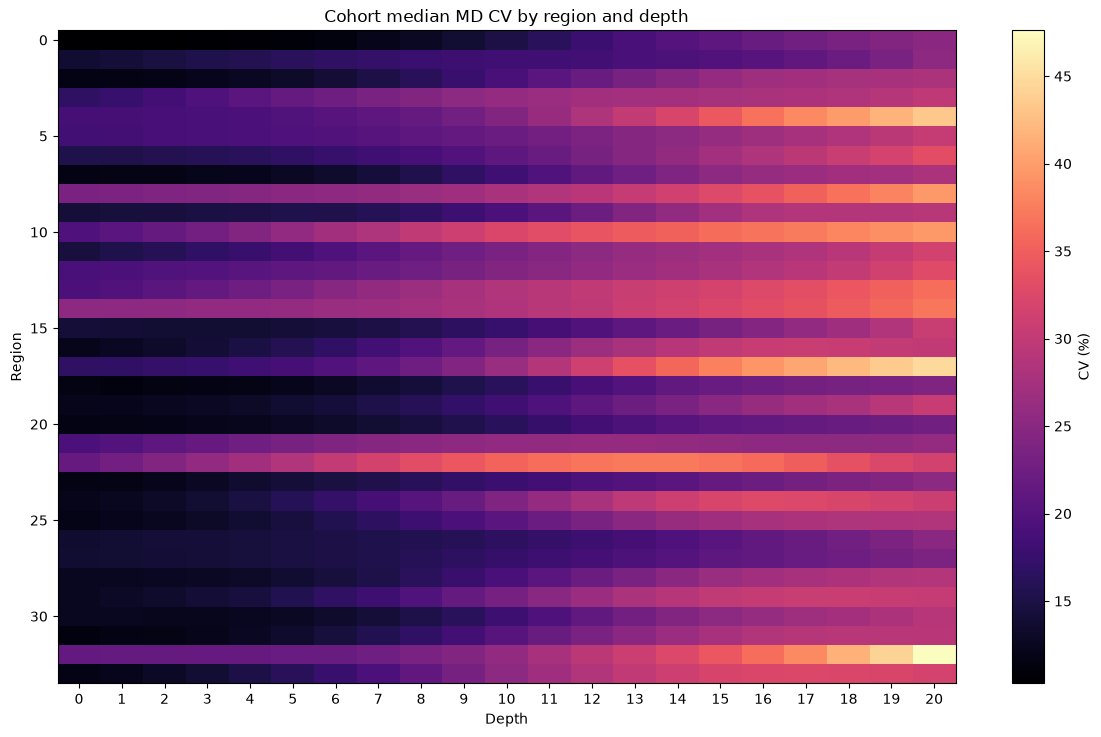

In [14]:
heat=depth.groupby(['region','depth'],as_index=False).cv_pct.median().pivot(index='region',columns='depth',values='cv_pct')
fig,ax=plt.subplots(figsize=(12,max(7,.22*len(heat))))
im=ax.imshow(heat,aspect='auto',cmap='magma')
ax.set(title='Cohort median MD CV by region and depth',xlabel='Depth',ylabel='Region')
ax.set_xticks(range(21)); ax.set_xticklabels(range(21))
fig.colorbar(im,ax=ax,label='CV (%)'); fig.tight_layout(); fig.savefig(ROOT/'cv_heatmap.png',dpi=180); plt.show()

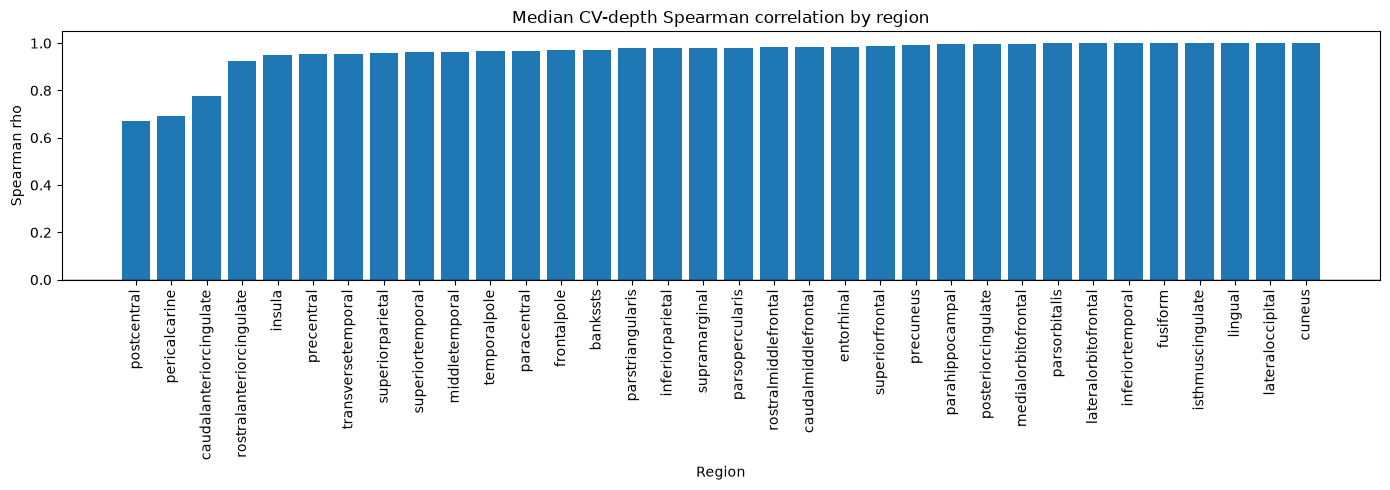

In [15]:
g=region.groupby('region',as_index=False).cv_depth_spearman_rho.median().sort_values('cv_depth_spearman_rho')
fig,ax=plt.subplots(figsize=(14,5)); ax.bar(g.region,g.cv_depth_spearman_rho); ax.axhline(0,color='black',lw=1)
ax.set(title='Median CV-depth Spearman correlation by region',xlabel='Region',ylabel='Spearman rho'); ax.tick_params(axis='x',rotation=90)
fig.tight_layout(); fig.savefig(ROOT/'cv_depth_spearman_by_region.png',dpi=180); plt.show()

## Overall CV-depth curve

At each depth, the line is the median CV across all subject × hemisphere × region observations. The shaded interval is the interquartile range. Depth 0 is the white surface and depth 20 is the pial surface.


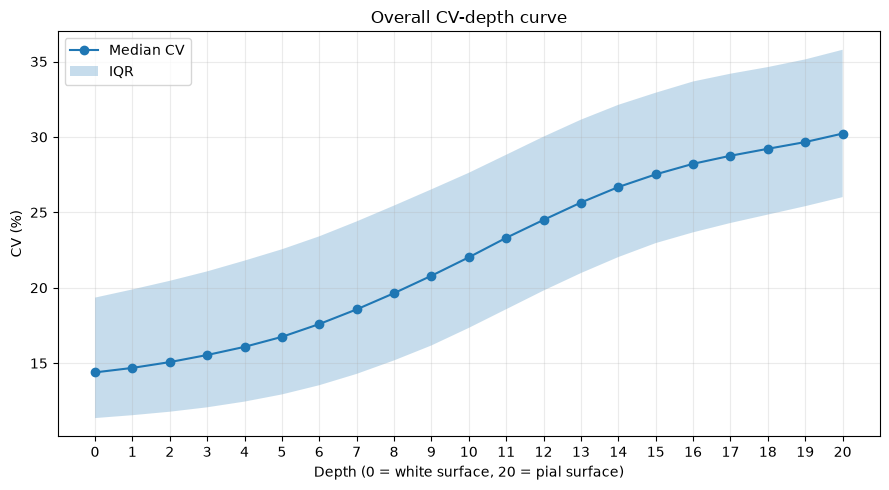

In [16]:
overall = depth.groupby('depth')['cv_pct'].agg(q25=lambda x: x.quantile(.25), median='median', q75=lambda x: x.quantile(.75)).reset_index()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(overall['depth'], overall['median'], marker='o', label='Median CV')
ax.fill_between(overall['depth'], overall['q25'], overall['q75'], alpha=.25, label='IQR')
ax.set(title='Overall CV-depth curve', xlabel='Depth (0 = white surface, 20 = pial surface)', ylabel='CV (%)')
ax.set_xticks(range(21)); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(ROOT/'overall_cv_depth_curve.png', dpi=180); plt.show()


## Mean, SD, and CV across depth

Each curve is the median across subject × hemisphere × region observations. The three panels retain their own y-axis because MD mean, SD, and CV have different units.


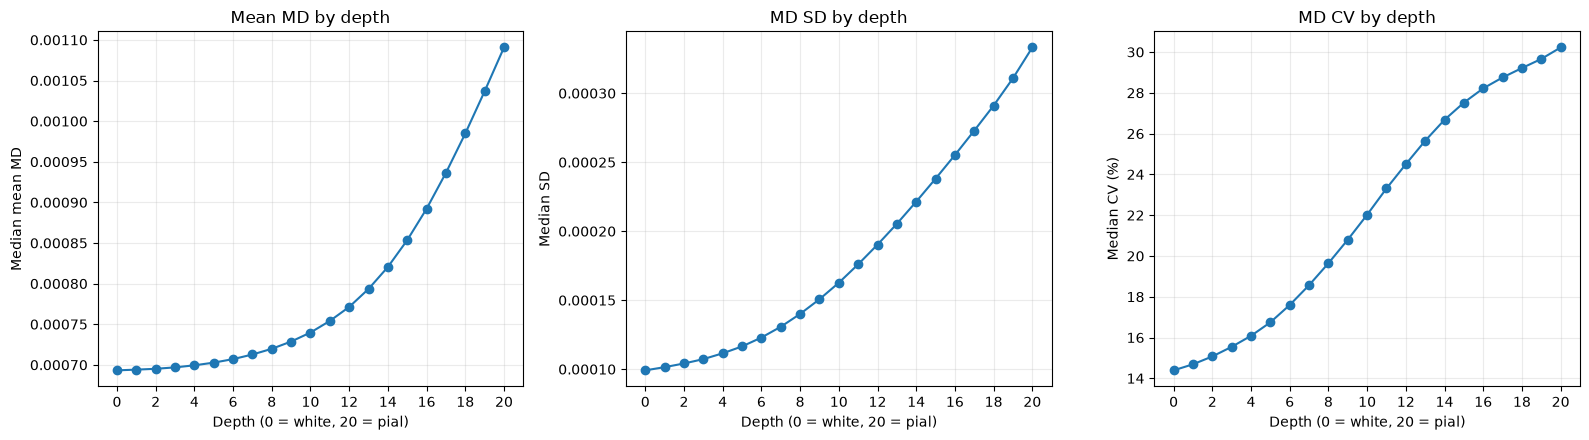

In [17]:
overall_stats = depth.groupby('depth', as_index=False).agg(mean_md=('mean_md','median'), sd_md=('sd_md','median'), cv_pct=('cv_pct','median'))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, column, title, ylabel in zip(axes, ['mean_md','sd_md','cv_pct'], ['Mean MD by depth','MD SD by depth','MD CV by depth'], ['Median mean MD','Median SD','Median CV (%)']):
    ax.plot(overall_stats['depth'], overall_stats[column], marker='o')
    ax.set(title=title, xlabel='Depth (0 = white, 20 = pial)', ylabel=ylabel); ax.set_xticks(range(0,21,2)); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(ROOT/'overall_mean_sd_cv_depth_curves.png', dpi=180); plt.show()


## Pial-depth exclusion sensitivity

This tests whether the CV-depth trend is driven mainly by the pial endpoint. For each subject × hemisphere × region, Spearman correlation is recalculated after removing 0, 1, 2, or 3 pial-side depth points.


,pial_depths_removed,median_rho,q25_rho,q75_rho,positive_rho_pct,n_subject_region
0,0,0.981818,0.896104,1.0,97.944633,20337
1,1,0.986466,0.905263,1.0,97.969219,20337
2,2,0.992982,0.912281,1.0,97.880710,20337
3,3,0.997936,0.927761,1.0,97.792201,20337


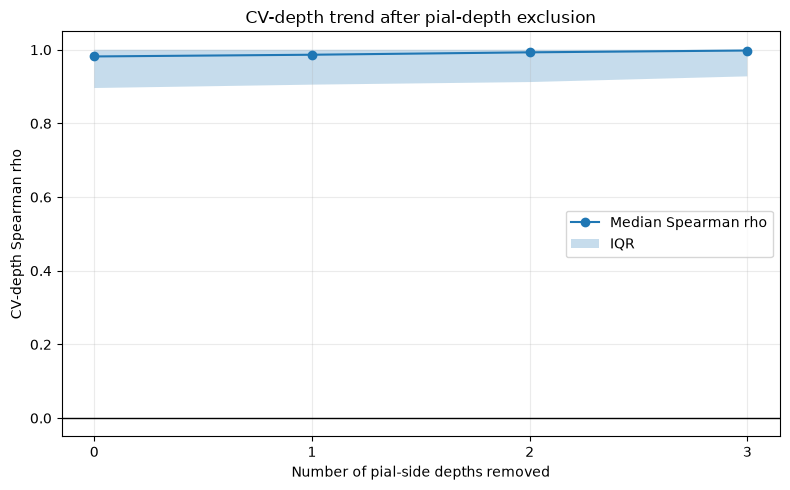

In [18]:
rows = []
for removed in range(4):
    subset = depth[depth['depth'] <= 20 - removed]
    rho = subset.groupby(['subject','hemisphere','region']).apply(lambda g: g['depth'].corr(g['cv_pct'], method='spearman'), include_groups=False).rename('rho').reset_index()
    rows.append({'pial_depths_removed': removed, 'median_rho': rho['rho'].median(), 'q25_rho': rho['rho'].quantile(.25), 'q75_rho': rho['rho'].quantile(.75), 'positive_rho_pct': 100*(rho['rho'] > 0).mean(), 'n_subject_region': len(rho)})
pial_sensitivity = pd.DataFrame(rows)
pial_sensitivity.to_csv(ROOT/'pial_depth_exclusion_sensitivity.csv', index=False)
display(pial_sensitivity)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pial_sensitivity['pial_depths_removed'], pial_sensitivity['median_rho'], marker='o', label='Median Spearman rho')
ax.fill_between(pial_sensitivity['pial_depths_removed'], pial_sensitivity['q25_rho'], pial_sensitivity['q75_rho'], alpha=.25, label='IQR')
ax.axhline(0, color='black', lw=1); ax.set(title='CV-depth trend after pial-depth exclusion', xlabel='Number of pial-side depths removed', ylabel='CV-depth Spearman rho', xticks=range(4))
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'pial_depth_exclusion_sensitivity.png', dpi=180); plt.show()


## Depth 0–17 CV change

For each subject × hemisphere × region, this compares mean CV at depths 0–2 with mean CV at depths 15–17. Depths 18–20 are excluded.


,n_subject_region,median_delta_cv_pct,q25_delta_cv_pct,q75_delta_cv_pct,positive_delta_pct
0,20337,12.197532,8.283604,16.468012,98.205242


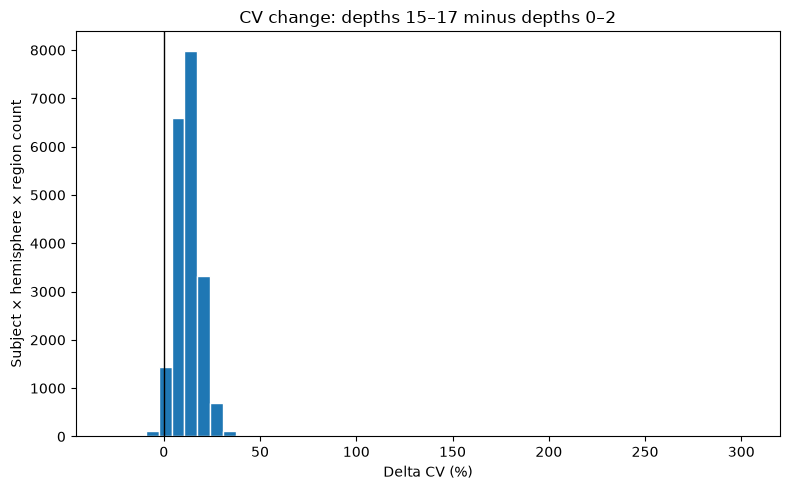

In [19]:
low = depth[depth['depth'].between(0, 2)].groupby(['subject','hemisphere','region'], as_index=False)['cv_pct'].mean().rename(columns={'cv_pct':'mean_cv_depth_0_2'})
high = depth[depth['depth'].between(15, 17)].groupby(['subject','hemisphere','region'], as_index=False)['cv_pct'].mean().rename(columns={'cv_pct':'mean_cv_depth_15_17'})
cv_delta_0_17 = low.merge(high, on=['subject','hemisphere','region'])
cv_delta_0_17['delta_cv_15_17_minus_0_2'] = cv_delta_0_17['mean_cv_depth_15_17'] - cv_delta_0_17['mean_cv_depth_0_2']
cv_delta_0_17.to_csv(ROOT/'cv_delta_depth_0_17_by_subject_region.csv', index=False)
delta_summary = pd.DataFrame([{'n_subject_region':len(cv_delta_0_17), 'median_delta_cv_pct':cv_delta_0_17['delta_cv_15_17_minus_0_2'].median(), 'q25_delta_cv_pct':cv_delta_0_17['delta_cv_15_17_minus_0_2'].quantile(.25), 'q75_delta_cv_pct':cv_delta_0_17['delta_cv_15_17_minus_0_2'].quantile(.75), 'positive_delta_pct':100*(cv_delta_0_17['delta_cv_15_17_minus_0_2']>0).mean()}])
display(delta_summary)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(cv_delta_0_17['delta_cv_15_17_minus_0_2'], bins=50, edgecolor='white')
ax.axvline(0, color='black', lw=1); ax.set(title='CV change: depths 15–17 minus depths 0–2', xlabel='Delta CV (%)', ylabel='Subject × hemisphere × region count')
fig.tight_layout(); fig.savefig(ROOT/'cv_delta_depth_0_17_distribution.png', dpi=180); plt.show()
